# Output figures v3 - Granular Computing image matting for mammogram masses
Figures 2-7. Figure 1 (pipeline flowchart) is your PDF and is not made here.

## How to use this notebook

**Run order:** (1) the *main cell*, (2) the *helpers cell*, then any figure. Each figure has its own pair of cells: a **CONTROLS** cell (the only one you edit) and a **DRAW** cell (run it, do not edit). Figures are independent: change Figure 5 without touching Figure 3, and run them in any order.

| Figure | What it shows | Data it needs |
|---|---|---|
| 1 | Pipeline flowchart | not made here (your PDF) |
| 2 | Layer 5 on one MIAS case | MIAS files on Drive |
| 3 | CBIS-DDSM results grid (full width) | CBIS-DDSM files on Drive |
| 4 | Seed-information sweep | none, hard-coded in the main cell |
| 5 | Classifier AUC on the unknown band | none, hard-coded |
| 6 | Granule ceiling | none, hard-coded |
| 7 | Per-image paired Dice difference | `seed_sweep_per_image.csv` on Drive |

**What each CONTROLS cell lets you change** (names are the same in every cell, so what you learn once applies everywhere):

* `FIG_W`, `FIG_H` - figure width and height in **inches**. Springer: single column = 3.3, full width = 6.85. Grid figures (2, 3) compute the height from the panels, so they have `FIG_W` only.
* `FONT = dict(...)` - font sizes in **points**, one entry per kind of text (title, axis label, tick, legend, annotation). Raise one number to enlarge only that text.
* `GAP_X`, `GAP_Y` (grids) - space between panels in **inches**. `LEFT`, `RIGHT`, `TOP`, `BOTTOM` - outer margins in inches (room for row labels, header bands, legend).
* `LINE_W`, `MARKER_S`, `CONTOUR_LW` - line width, marker size, contour width.
* `COLUMNS`, `PANELS`, `CLASS_ROWS` - which panels or rows to draw, and in which order. Removing a name removes the panel and the grid re-flows.
* `SHOW_...` switches - `True` / `False` to turn optional items on or off.
* `YLIM`, `XLIM` - axis ranges; `None` means automatic.

Colours, method names and all result numbers live in the **main cell**; change them there and every figure follows. Files are saved to the `grc_report_figures_v3` folder on Drive as 300-dpi PNG and as vector PDF.

In [46]:
!pip install -q pymupdf

# =====================================================================================================
#  MAIN CELL  -  run this first. It holds everything shared by the figures:
#    1) imports and Drive location      2) colours      3) base text style      4) hard-coded results
#  Per-figure sizes, fonts and styles are NOT here: each figure has its own CONTROLS cell (see the
#  instruction cell above) so that one figure can be changed without touching the others.
# =====================================================================================================
import pymupdf
import os, re, json, shutil, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
warnings.filterwarnings('ignore')

# ---------------------------------------------- 1) where things live ---------------------------------
try:
    from google.colab import files, drive
    drive.mount('/content/drive', force_remount=False)
    DRIVE = '/content/drive/MyDrive'
except Exception:
    DRIVE = os.environ.get('GRC_DRIVE', '.')
FIG_OUT     = DRIVE + '/grc_report_figures_v3'            # all figures are written here (PNG 300 dpi + PDF)
DDSM_ROOT   = DRIVE + '/cbis_ddsm_grc_project_v3_dicom'   # CBIS-DDSM project folder (Figures 3 and 7)
MIAS_ROOT   = DRIVE + '/mias_grc_project_v3_cv'           # MIAS project folder (Figure 2)
MIAS_K_TAG  = 'K8'                                        # MIAS results sub-folder
os.makedirs(FIG_OUT, exist_ok=True)
print('Figures will be written to:', FIG_OUT)

# ---------------------------------------------- 2) colours (same in every figure) --------------------
PALETTE = {'blue': '#0072B2', 'orange': '#E69F00', 'green': '#009E73', 'verm': '#D55E00',
           'sky': '#56B4E9', 'purple': '#CC79A7', 'grey': '#8C8C8C', 'dark': '#333333'}
CLASS_COL = {'CIRC': PALETTE['blue'], 'MISC': PALETTE['green'], 'SPIC': PALETTE['verm']}
METHOD_STYLE = {                                          # one entry per method: name, colour, marker, line style
    'seed_only'  : dict(label='Seed-only fill',          color=PALETTE['dark'],   marker='o', ls='-'),
    'closed_form': dict(label='Closed-form matting',     color=PALETTE['purple'], marker='s', ls='--'),
    'no_hybrid'  : dict(label='Layer 5, no hybrid prior', color=PALETTE['sky'],    marker='^', ls='--'),
    'full'       : dict(label='Full method',             color=PALETTE['verm'],   marker='D', ls='-')}
GT_CONTOUR_COLOR, PRED_CONTOUR_COLOR = '#00FF66', '#FFEB00'    # reference / predicted contour on grey images
ERROR_COLORS = {'agreement': [1.0, 1.0, 1.0], 'gt_only': [0.85, 0.0, 0.0], 'prediction_only': [0.0, 0.6, 0.9]}
ERROR_BG     = [0.07, 0.07, 0.07]

# ---------------------------------------------- 3) base text style ------------------------------------
BASE_FONT = 7.5      # default font size (pt) for every figure; a figure's own FONT dict overrides it
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': BASE_FONT, 'axes.titlesize': BASE_FONT, 'axes.titleweight': 'semibold',
    'axes.labelsize': BASE_FONT, 'xtick.labelsize': BASE_FONT - 0.5, 'ytick.labelsize': BASE_FONT - 0.5,
    'legend.fontsize': BASE_FONT - 1, 'axes.linewidth': 0.7, 'xtick.major.width': 0.7, 'ytick.major.width': 0.7,
    'xtick.major.size': 2.5, 'ytick.major.size': 2.5, 'axes.grid': True, 'grid.alpha': 0.22, 'grid.linestyle': ':',
    'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False,
    'figure.facecolor': 'white', 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'savefig.facecolor': 'white'})

def save(fig, name):
    for ext in ('png', 'pdf'):
        fig.savefig(os.path.join(FIG_OUT, f'{name}.{ext}'))
    print(f'  saved {name}.png / .pdf')

# ---------------------------------------------- 4) hard-coded results (Figures 4, 5, 6) ---------------
# Update a number here and every figure that uses it changes. Sources are named in the comments.

# Figure 4: seed-information sweep. Mean Dice per method and seed setting.
#   CBIS-DDSM: Notebook 5 table "MEAN DICE (test)", 269 test images.   MIAS: MIAS Notebook 3, 55 images, out-of-fold.
SEED_SETTINGS = ['6/10', '12/20', '20/30', '30/45', 'click + box']       # px eroded inside / dilated outside; last = click + loose box
SEED_MEAN = {
    'CBIS-DDSM': {'seed_only':   [0.8009, 0.6490, 0.5270, 0.3950, 0.6539],
                  'closed_form': [0.5981, 0.3792, 0.3008, 0.2796, 0.5154],
                  'no_hybrid':   [0.7581, 0.5404, 0.3718, 0.2286, 0.6082],
                  'full':        [0.7511, 0.5295, 0.3644, 0.2227, 0.6073]},
    'MIAS':      {'seed_only':   [0.9575, 0.9280, 0.9143, 0.8572, 0.6830],
                  'closed_form': [0.9499, 0.8964, 0.7987, 0.7383, 0.4544],
                  'no_hybrid':   [0.9241, 0.8278, 0.7338, 0.6629, 0.6659],
                  'full':        [0.9248, 0.8284, 0.7344, 0.6634, 0.6717]}}
# Paired difference, full method minus seed-only fill: (mean, ci_low, ci_high) per setting, patient-level bootstrap (same notebooks)
SEED_GAP = {
    'CBIS-DDSM': [(-0.0498, -0.0638, -0.0367), (-0.1195, -0.1384, -0.1019), (-0.1626, -0.1797, -0.1455),
                  (-0.1723, -0.1888, -0.1557), (-0.0466, -0.0636, -0.0302)],
    'MIAS':      [(-0.0328, -0.0443, -0.0230), (-0.0996, -0.1226, -0.0791), (-0.1798, -0.2217, -0.1461),
                  (-0.1937, -0.2515, -0.1464), (-0.0113, -0.0794, +0.0461)]}
UNKNOWN_FRAC = {'CBIS-DDSM': [0.11, 0.23, 0.38, 0.64, 0.18], 'MIAS': [0.24, 0.49, 0.68, 0.85, 0.70]}   # mean share of the ROI left unknown
SEED_N = {'CBIS-DDSM': 269, 'MIAS': 55}

# Figure 5: classifier AUC on the unknown band (0.5 = chance). CBIS-DDSM: Notebook 7, test split, 95% patient-level interval.
#   (label, band AUC, ci_low, ci_high, validation AUC inside the seeds)
AUC_DDSM = [('R0 SVM (main)',         0.497, 0.484, 0.511, 0.562), ('R1 SVM, band rows',       0.485, 0.472, 0.498, 0.630),
            ('T1 boosting',           0.492, 0.480, 0.504, 0.651), ('T2 boosting, band rows',  0.498, 0.485, 0.510, 0.646),
            ('T3 MLP, band rows',     0.496, 0.486, 0.506, 0.623), ('N1 CNN',                  0.495, 0.477, 0.511, 0.839),
            ('N2 CNN, band rows',     0.463, 0.449, 0.480, 0.817), ('N3 CNN, ROI only',        0.496, 0.479, 0.512, 0.810)]
#   MIAS: MIAS Notebook 2, held-out folds.  (label, band AUC, ci_low, ci_high)
AUC_MIAS = [('manual 3x3', 0.579, 0.556, 0.603), ('single 5x5', 0.584, 0.559, 0.617),
            ('six-channel', 0.588, 0.561, 0.616), ('intensity only', 0.566, 0.547, 0.589)]
AUC_CHANCE, AUC_USEFUL = 0.5, 0.6                    # reading rule fixed in advance: detectable if the interval is above 0.5, useful above 0.6

# Figure 6: granule ceiling, all 1,067 lesion images, Notebook 9. Per granule side (px): (mean, ci_low, ci_high)
GRANULE_SIDES = [4, 6, 8, 12, 16]
GRANULE = {'slic': [(0.866, 0.859, 0.873), (0.784, 0.770, 0.797), (0.725, 0.708, 0.741), (0.553, 0.529, 0.575), (0.434, 0.409, 0.458)],
           'grid': [(0.880, 0.875, 0.886), (0.821, 0.810, 0.831), (0.789, 0.779, 0.799), (0.570, 0.548, 0.591), (0.435, 0.411, 0.459)],
           'seed_only': (0.759, 0.744, 0.773)}
GRANULE_RULE = 0.05                                   # declared rule: ceiling must beat seed-only by +0.05 (and a plain grid by +0.02)
print('Main cell done.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Figures will be written to: /content/drive/MyDrive/grc_report_figures_v3
Main cell done.


In [47]:
# =====================================================================================================
#  HELPERS  -  run once after the main cell. Nothing here draws a figure; there is nothing to edit.
#  Loaders read the saved outputs of the main notebooks and are called only by the figures that need images
#  (Figures 2, 3, 7). Figures 4, 5, 6 use the hard-coded results of the main cell and need no Drive data.
# =====================================================================================================
from scipy.sparse import csr_matrix, diags, identity
from scipy.sparse.linalg import spsolve
from scipy.ndimage import distance_transform_edt
from numpy.lib.stride_tricks import sliding_window_view
import math

# ---- constants of the evaluated pipeline (same values as the main notebooks) ----
LAP_WINDOW, LAP_EPSILON = 3, 1e-7
MAX_NODES, LAMBDA_PROPAGATION, HYBRID_GAMMA, ALPHA_THRESHOLD = 2500, 100.0, 0.9, 0.5
EVAL_ERODE, EVAL_DILATE = 6, 10                          # default evaluation seeds ('band 6/10')
K3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
MAIN_VARIANT = dict(mu=1.0, w_int=1 - HYBRID_GAMMA)      # 'paper_hybrid_mu1'

_FIND_CACHE = {}
def find(root, name, prefer=None):
    """Find a saved output by file name anywhere below root (robust to the folder layout)."""
    key = (root, name, prefer)
    if key in _FIND_CACHE: return _FIND_CACHE[key]
    hits = [os.path.join(dp, name) for dp, _, fs in os.walk(root) if name in fs]
    if prefer: hits = sorted(hits, key=lambda p: (prefer not in p, len(p)))
    if not hits: raise FileNotFoundError(f'{name} not found under {root}. Run the notebook that writes it first.')
    _FIND_CACHE[key] = hits[0]; return hits[0]

# ---- loaders (lazy: nothing is read until a figure asks for it) ----
def load_ddsm():
    d = {'roi': np.load(find(DDSM_ROOT, 'rois.npz')), 'gt': np.load(find(DDSM_ROOT, 'gt_masks.npz')),
         'alpha': np.load(find(DDSM_ROOT, 'alpha_maps_full.npz')),           # full-method alpha maps of the test images (Notebook 4)
         'eval': pd.read_csv(find(DDSM_ROOT, 'evaluation_per_image.csv'))}   # full method, Dice per test image
    try: d['tri'] = np.load(find(DDSM_ROOT, 'trimaps_eval.npz'))
    except FileNotFoundError: d['tri'] = None
    try: d['ell_r'] = float(json.load(open(find(DDSM_ROOT, 'seedfree_selected_params.json')))['ellipse_radius'])
    except FileNotFoundError: d['ell_r'] = None
    return d

def load_mias():
    df = pd.read_csv(find(MIAS_ROOT, 'final_df_loaded.csv'))
    return {'roi': np.load(find(MIAS_ROOT, 'rois.npz')), 'gt': np.load(find(MIAS_ROOT, 'gt_masks.npz')),
            'oof': np.load(find(MIAS_ROOT, 'oof_prob_maps.npz', MIAS_K_TAG)),   # out-of-fold probability maps
            'res': pd.read_csv(find(MIAS_ROOT, 'per_image_results.csv', MIAS_K_TAG)), 'cls': dict(zip(df['image_id'], df['class']))}

def load_sweep():
    return pd.read_csv(find(DDSM_ROOT, 'seed_sweep_per_image.csv'))             # Notebook 5, per image, per method, per seed setting

# ---- Layer 5 and the seed-only control (copied from Notebooks 4 and 5) ----
def _downscale_trimap(trimap, hs, ws):
    h0, w0 = trimap.shape
    tm_s = cv2.resize(trimap, (ws, hs), interpolation=cv2.INTER_NEAREST)
    fg0 = np.argwhere(trimap == 255)
    if len(fg0) and not (tm_s == 255).any():
        cy, cx = fg0.mean(axis=0)
        tm_s[min(hs - 1, int(cy * hs / h0)), min(ws - 1, int(cx * ws / w0))] = 255
    return tm_s

def build_matting_laplacian(feat, win=LAP_WINDOW, eps=LAP_EPSILON):
    h, w = feat.shape; n = h * w; k = win * win
    idx = np.arange(n).reshape(h, w)
    iw = sliding_window_view(idx, (win, win)).reshape(-1, k)
    fw = sliding_window_view(feat.astype(np.float64), (win, win)).reshape(-1, k)
    mu = fw.mean(axis=1, keepdims=True); var = fw.var(axis=1, keepdims=True) + eps / k; d = fw - mu
    W = (1.0 + d[:, :, None] * d[:, None, :] / var[:, :, None]) / k
    vals = np.eye(k)[None] - W
    rows = np.repeat(iw[:, :, None], k, axis=2).ravel(); cols = np.repeat(iw[:, None, :], k, axis=1).ravel()
    return csr_matrix((vals.ravel(), (rows, cols)), shape=(n, n))

def _grid_size(shape, max_nodes=MAX_NODES):
    h0, w0 = shape; s = min(1.0, math.sqrt(max_nodes / float(h0 * w0)))
    return max(8, int(round(h0 * s))), max(8, int(round(w0 * s)))

def solve_alpha_trace(prob_map, trimap, roi, variant=MAIN_VARIANT, max_nodes=MAX_NODES, lam=LAMBDA_PROPAGATION):
    """Layer 5 exactly as in Notebook 4, but also returns the probability map and the refined alpha for display."""
    h0, w0 = prob_map.shape; hs, ws = _grid_size((h0, w0), max_nodes)
    prob_s = cv2.resize(prob_map, (ws, hs), interpolation=cv2.INTER_LINEAR)
    roi_s = cv2.resize(roi, (ws, hs), interpolation=cv2.INTER_LINEAR)
    tm_s = _downscale_trimap(trimap, hs, ws)
    inten = roi_s.astype(np.float32); rg = inten.max() - inten.min()
    inten = (inten - inten.min()) / rg if rg > 1e-8 else np.zeros_like(inten)
    L = build_matting_laplacian(roi_s)
    known = ((tm_s == 255) | (tm_s == 0)).ravel().astype(np.float64); target = (tm_s == 255).ravel().astype(np.float64)
    a0 = (1 - variant['w_int']) * prob_s + variant['w_int'] * inten
    A = L + lam * diags(known) + variant['mu'] * identity(hs * ws, format='csr')
    b = lam * known * target + variant['mu'] * a0.ravel().astype(np.float64)
    alpha = np.clip(spsolve(A.tocsc(), b).reshape(hs, ws), 0, 1).astype(np.float32)
    return {'prob': prob_map.astype(np.float32), 'alpha': cv2.resize(alpha, (w0, h0), interpolation=cv2.INTER_LINEAR)}

def trimap_only_alpha(trimap):
    fg, bg = trimap == 255, trimap == 0
    alpha = np.zeros(trimap.shape, np.float32); alpha[fg] = 1.0; unk = ~(fg | bg)
    d_fg, d_bg = distance_transform_edt(~fg), distance_transform_edt(~bg)
    alpha[unk] = (d_bg / np.maximum(d_fg + d_bg, 1e-6))[unk]
    return alpha

def seed_only_fill(trimap, max_nodes=MAX_NODES):
    h0, w0 = trimap.shape; hs, ws = _grid_size((h0, w0), max_nodes)
    a = trimap_only_alpha(_downscale_trimap(trimap, hs, ws))
    return cv2.resize(a, (w0, h0), interpolation=cv2.INTER_LINEAR).astype(np.float32)

def _erode_capped(mask, n):
    out = mask.copy()
    for _ in range(n):
        nxt = cv2.erode(out, K3)
        if nxt.sum() == 0: break
        out = nxt
    return out

def make_eval_trimap(gt, erode=EVAL_ERODE, dilate=EVAL_DILATE):
    mask = (gt > 127).astype(np.uint8); tm = np.full(mask.shape, 128, np.uint8)
    tm[cv2.dilate(mask, K3, iterations=dilate) == 0] = 0; tm[_erode_capped(mask, erode) == 1] = 255
    return tm

def radial(shape):
    h, w = shape; yy, xx = np.mgrid[:h, :w].astype(np.float32)
    return np.sqrt(((yy - (h - 1) / 2) / (h / 2)) ** 2 + ((xx - (w - 1) / 2) / (w / 2)) ** 2)

# ---- small utilities ----
def dice_iou(pred, gt):
    inter = np.logical_and(pred, gt).sum(); union = np.logical_or(pred, gt).sum(); s = pred.sum() + gt.sum()
    return (inter / union if union else np.nan), (2 * inter / s if s else np.nan)

def fit_to(a, shape, nearest=True):
    return a if a.shape[:2] == tuple(shape) else cv2.resize(a, (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST if nearest else cv2.INTER_LINEAR)

def pwin(a, lo=1, hi=99):
    """Percentile window to [0, 1] for display (always float32)."""
    a = np.asarray(a, np.float32); l, h = np.percentile(a, [lo, hi])
    return (np.clip((a - l) / (h - l), 0, 1) if h > l else np.zeros_like(a)).astype(np.float32)

def class_median_case(df, cls, col='dice'):
    """Selection rule for the qualitative figures: the held-out case whose Dice is closest to the class median."""
    d = df[df['class'] == cls].dropna(subset=[col]); tgt = d[col].median()
    return d.loc[(d[col] - tgt).abs().idxmin(), 'image_id']

def square(a, fill=0.0):
    h, w = a.shape[:2]; s = max(h, w); ph, pw = (s - h) // 2, (s - w) // 2
    return np.pad(a, ((ph, s - h - ph), (pw, s - w - pw)) + ((0, 0),) * (a.ndim - 2), mode='constant', constant_values=fill)

def clean_axes(ax, border='#BBBBBB', lw=0.5):
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(True); s.set_linewidth(lw); s.set_color(border)

def error_rgb(pred, gt):
    rgb = np.ones(pred.shape + (3,), np.float32) * np.array(ERROR_BG, np.float32)
    rgb[np.logical_and(pred, gt)] = ERROR_COLORS['agreement']; rgb[np.logical_and(~pred, gt)] = ERROR_COLORS['gt_only']; rgb[np.logical_and(pred, ~gt)] = ERROR_COLORS['prediction_only']
    return rgb
print('Helpers ready.')

# ---- layout in inches (used by the grid-style Figures 2 and 3) ----
def make_grid(fig_w, nrows, ncols, left, right, top, bottom, gap_x, gap_y, aspect=1.0):
    """Panels of equal size placed by absolute inches, so spacing never depends on the content.
       Returns fig, axes[row][col], and the geometry (panel_w, panel_h, fig_h) in inches."""
    pw = (fig_w - left - right - (ncols - 1) * gap_x) / ncols; ph = pw * aspect
    fig_h = top + bottom + nrows * ph + (nrows - 1) * gap_y
    fig = plt.figure(figsize=(fig_w, fig_h)); axes = []
    for r in range(nrows):
        row = []
        for c in range(ncols):
            x0 = left + c * (pw + gap_x); y0 = fig_h - top - (r + 1) * ph - r * gap_y
            row.append(fig.add_axes([x0 / fig_w, y0 / fig_h, pw / fig_w, ph / fig_h]))
        axes.append(row)
    return fig, axes, (pw, ph, fig_h)

def show(ax, rgb_or_gray, cmap='gray', vmin=0, vmax=1):
    ax.imshow(rgb_or_gray, cmap=cmap, vmin=vmin, vmax=vmax, interpolation='nearest'); clean_axes(ax)

def draw_contour(ax, mask, color, lw=1.0):
    if mask.any():
        ax.contour(mask.astype(np.float32), levels=[0.5], colors=[color], linewidths=lw)
    h, w = mask.shape; ax.set_xlim(-0.5, w - 0.5); ax.set_ylim(h - 0.5, -0.5)

def tint(rgb, mask, color, strength):
    out = rgb.copy(); out[mask] = (1 - strength) * out[mask] + strength * np.array(mcolors.to_rgb(color), np.float32); return out
import matplotlib.colors as mcolors

Helpers ready.


## Figure 2 - Layer 5 on one MIAS case (single column)
Edit only the **CONTROLS** cell; then run the **DRAW** cell.

Figure 2: MIAS MDB145 (SPIC); Dice of this case = 0.947
  alpha in the unknown band (4576 px): 1% above 0.95, 2% below 0.05, 97% in between   (saturated = little visible refinement)
  saved fig02_mias_layer5_illustration.png / .pdf


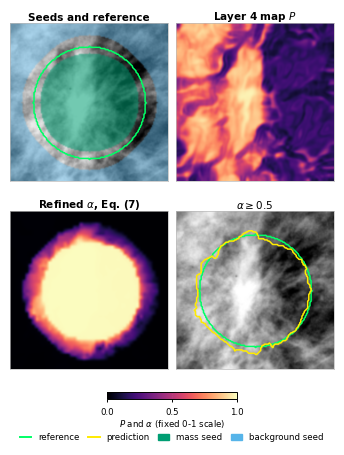

In [48]:
# ################ CELL 1 of 2: FIGURE 2 CONTROLS (paste into the existing CONTROLS cell, run) ################
# ======================= FIGURE 2  -  CONTROLS (edit here) : Layer 5 on one MIAS case =================
F2_CASE_CLASS = 'SPIC'                 # 'CIRC', 'MISC' or 'SPIC': the class-median case of this class is shown
F2_PANELS     = ['seeds', 'prob', 'alpha', 'final']   # order and choice of panels: 'roi', 'seeds', 'prob', 'alpha', 'final'
F2_N_COLS     = 2                      # panels per row (2 -> 2x2 grid, 4 -> one row of four)

F2_FIG_W      = 3.3                    # figure width in inches (3.3 = Springer single column)
F2_GAP_X      = 0.08                   # horizontal space between panels, inches
F2_GAP_Y      = 0.30                   # vertical space between panels, inches (leave room for the titles)
F2_LEFT, F2_RIGHT, F2_TOP, F2_BOTTOM = 0.03, 0.03, 0.05, 0.80     # outer margins, inches (F2_BOTTOM holds colour bar + legend)
F2_FONT       = dict(title=7.5, legend=6.2)               # points
F2_IMAGE_INTERP = 'bicubic'            # 'bicubic' / 'lanczos' smooth, 'nearest' shows true pixels
F2_CONTOUR_LW = 1.1                    # width of reference / prediction contours
F2_SHOW_LEGEND = True
F2_ALPHA_BAND_ONLY = False              # True: alpha shown only in the unknown band (seed pixels are fixed at 0/1 and drawn dark grey), so the refinement is visible
F2_SHOW_COLORBAR = True                # one fixed 0-1 colour bar shared by the P and alpha panels
F2_CBAR_W = 1.3                        # colour-bar length, inches

def show(ax, rgb_or_gray, cmap='gray', vmin=0, vmax=1, interp='nearest'):
    ax.imshow(rgb_or_gray, cmap=cmap, vmin=vmin, vmax=vmax, interpolation=interp); clean_axes(ax)

# ################ CELL 2 of 2: FIGURE 2 DRAW (paste into the existing DRAW cell, run right after) ################
# ======================= FIGURE 2  -  DRAW (run, do not edit) =======================================
M = load_mias()
m_full = M['res'][M['res']['method'] == 'full_method']
iid = class_median_case(m_full, F2_CASE_CLASS)                 # class-median case by full-method Dice, not the best one
roi, gt = M['roi'][iid].astype(np.float32), (M['gt'][iid] > 127)
tm = make_eval_trimap(M['gt'][iid]); tr = solve_alpha_trace(M['oof'][iid].astype(np.float32), tm, roi)
pred = tr['alpha'] >= ALPHA_THRESHOLD; shape = roi.shape
print(f'Figure 2: MIAS {iid} ({F2_CASE_CLASS}); Dice of this case = {dice_iou(pred, fit_to(gt.astype(np.uint8), pred.shape).astype(bool))[1]:.3f}')

img = pwin(roi); base = np.dstack([img] * 3); tmf = fit_to(tm, shape)
seeds = tint(tint(base, tmf == 255, PALETTE['green'], 0.55), tmf == 0, PALETTE['sky'], 0.45)
band = (tmf == 128); n_b = band.sum(); a_b = tr['alpha'][band] if n_b else np.array([0.0])
print(f'  alpha in the unknown band ({n_b} px): {100*(a_b > 0.95).mean():.0f}% above 0.95, {100*(a_b < 0.05).mean():.0f}% below 0.05, '
      f'{100*((a_b >= 0.05) & (a_b <= 0.95)).mean():.0f}% in between   (saturated = little visible refinement)')
cm_a = plt.get_cmap('magma').copy(); cm_a.set_bad('#2b2b2b')
alpha_show = np.ma.masked_where(~band, tr['alpha']) if F2_ALPHA_BAND_ONLY else tr['alpha']
spec = {'roi':   ('ROI and reference',      base,        None,    [(gt, GT_CONTOUR_COLOR)]),
        'seeds': ('Seeds and reference',    seeds,       None,    [(gt, GT_CONTOUR_COLOR)]),
        'prob':  (r'Layer 4 map $P$',       tr['prob'],  'magma', []),
        'alpha': (r'Refined $\alpha$, Eq. (7)', alpha_show, cm_a, []),
        'final': (r'$\alpha \geq 0.5$',     base,        None,    [(gt, GT_CONTOUR_COLOR), (pred, PRED_CONTOUR_COLOR)])}
n = len(F2_PANELS); nc = min(F2_N_COLS, n); nr = int(np.ceil(n / nc))
fig, axes, geo = make_grid(F2_FIG_W, nr, nc, F2_LEFT, F2_RIGHT, F2_TOP, F2_BOTTOM, F2_GAP_X, F2_GAP_Y, aspect=shape[0] / shape[1])
for k, key in enumerate(F2_PANELS):
    ax = axes[k // nc][k % nc]; title, arr, cmap, cons = spec[key]
    show(ax, arr, cmap or 'gray', 0, 1, interp=F2_IMAGE_INTERP); ax.set_title(title, fontsize=F2_FONT['title'], pad=2.5)
    for m, col in cons: draw_contour(ax, fit_to(m.astype(np.uint8), shape).astype(bool), col, F2_CONTOUR_LW)
for k in range(n, nr * nc): axes[k // nc][k % nc].axis('off')
if F2_SHOW_COLORBAR and any(k in F2_PANELS for k in ('prob', 'alpha')):
    cax = fig.add_axes([(F2_FIG_W - F2_CBAR_W) / 2 / F2_FIG_W, 0.50 / geo[2], F2_CBAR_W / F2_FIG_W, 0.07 / geo[2]])
    cb = fig.colorbar(plt.cm.ScalarMappable(norm=mpl.colors.Normalize(0, 1), cmap='magma'), cax=cax, orientation='horizontal')
    cb.set_ticks([0, 0.5, 1]); cb.ax.tick_params(labelsize=F2_FONT['legend'], length=2); cb.set_label(r'$P$ and $\alpha$ (fixed 0-1 scale)', fontsize=F2_FONT['legend'], labelpad=1)
if F2_SHOW_LEGEND:
    h, l = [Line2D([0], [0], color=GT_CONTOUR_COLOR, lw=1.4), Line2D([0], [0], color=PRED_CONTOUR_COLOR, lw=1.4)], ['reference', 'prediction']
    if 'seeds' in F2_PANELS or 'roi' in F2_PANELS and False: h += [Patch(color=PALETTE['green']), Patch(color=PALETTE['sky'])]; l += ['mass seed', 'background seed']
    fig.legend(h, l, loc='lower center', ncol=len(h), fontsize=F2_FONT['legend'],
               bbox_to_anchor=(0.5, 0.0), handlelength=1.3, columnspacing=1.0)
save(fig, 'fig02_mias_layer5_illustration'); plt.show()

## Figure 3 - CBIS-DDSM results grid (full width)
Edit only the **CONTROLS** cell; then run the **DRAW** cell.

Selection rule: test image with full-method Dice closest to the class median (not hand-picked).
Selected (class-median Dice): {'CIRC': 'P_00061_RIGHT_1_MLO', 'MISC': 'P_01697_LEFT_1_MLO', 'SPIC': 'P_00802_LEFT_1_MLO', 'worst': 'P_00576_LEFT_1_CC'}
  saved fig03_ddsm_results_grid.png / .pdf


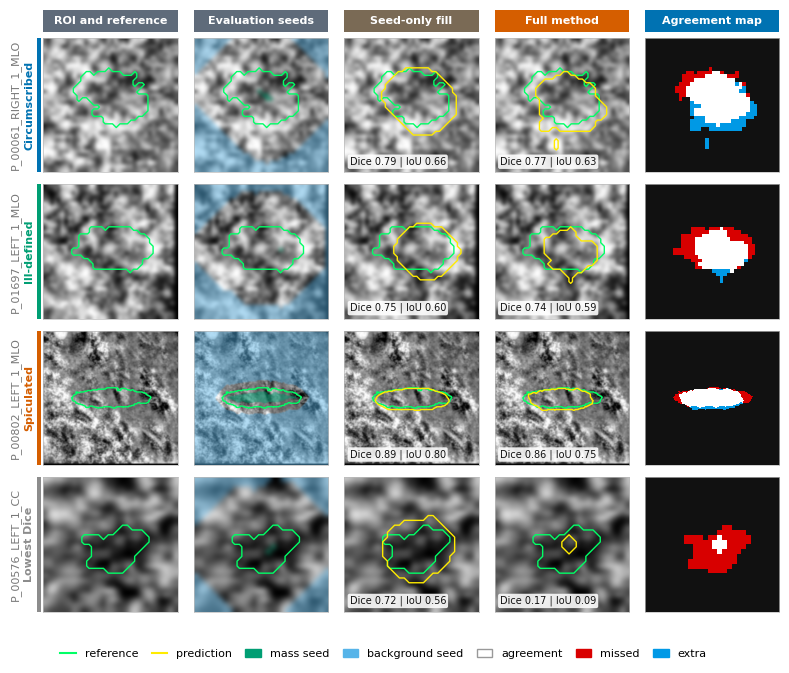

In [49]:
# ################ CELL 1 of 2: FIGURE 3 CONTROLS (paste into the existing CONTROLS cell, run) ################
# ======================= FIGURE 3  -  CONTROLS (edit here) : CBIS-DDSM results grid ===================
# Columns, left to right. Available: 'roi' (image + reference), 'seed' (evaluation seeds), 'seedonly' (seed-only fill),
# 'full' (full method + Dice/IoU badge), 'ellipse' (seed-free centre ellipse), 'alpha' (alpha map), 'error' (agreement map)
F3_COLUMNS     = ['roi', 'seed', 'seedonly', 'full', 'error']
F3_CLASS_ROWS  = ['CIRC', 'MISC', 'SPIC']       # one class-median test case per class; delete a name to drop the row
F3_SHOW_WORST  = True                          # True adds a bottom row: the lowest-Dice test case overall

F3_FIG_W       = 8                           # full width, inches
F3_LEFT        = 0.6                           # room for the coloured row labels, inches
F3_RIGHT, F3_BOTTOM = 0.04, 0.85                   # outer margins, inches (F3_BOTTOM holds the legend)
F3_GAP_X, F3_GAP_Y = 0.16, 0.12                    # space BETWEEN panels, inches: raise for more air, lower for a tighter grid
F3_HEADER_H, F3_HEADER_GAP = 0.22, 0.06            # height of the column title bands and their distance to the panels, inches
F3_CROP_MARGIN = 0.35                           # extra context around the lesion (fraction of its size); larger = lesion looks smaller
F3_CONTOUR_LW  = 1.0
F3_IMAGE_INTERP = 'bicubic'                     # smoothing of image panels: 'bicubic' or 'lanczos' (smooth), 'nearest' (shows the true pixels)
F3_FONT        = dict(col_title=8, row_label=8, row_id=8, badge=7, legend=8)     # points
F3_LEGEND_NCOL = 7                              # legend columns (raise to 7 for a single line)
F3_SHOW_BADGE  = True                           # Dice / IoU label on the 'full', 'seedonly' and 'ellipse' panels
F3_SHOW_IMAGE_ID = True
F3_SHOW_RULE_NOTE = False                        # one-line footnote stating how the cases were chosen                         # small image id under each row label
def show(ax, rgb_or_gray, cmap='gray', vmin=0, vmax=1, interp='nearest'):
    ax.imshow(rgb_or_gray, cmap=cmap, vmin=vmin, vmax=vmax, interpolation=interp); clean_axes(ax)

F3_COLUMN_TITLES = {'roi': 'ROI and reference', 'seed': 'Evaluation seeds', 'seedonly': 'Seed-only fill', 'full': 'Full method',
                 'ellipse': 'Seed-free ellipse', 'alpha': r'$\alpha$ map', 'error': 'Agreement map'}
F3_COLUMN_COLORS = {'roi': '#5F6B7A', 'seed': '#5F6B7A', 'seedonly': '#7A6A55', 'full': PALETTE['verm'],
                 'ellipse': '#7A6A55', 'alpha': PALETTE['verm'], 'error': PALETTE['blue']}
F3_CLASS_NAMES = {'CIRC': 'Circumscribed', 'MISC': 'Ill-defined', 'SPIC': 'Spiculated'}

# ################ CELL 2 of 2: FIGURE 3 DRAW (paste into the existing DRAW cell, run right after) ################
# ======================= FIGURE 3  -  DRAW (run, do not edit) =======================================
D = load_ddsm(); ev = D['eval']
have_alpha = set(D['alpha'].files)
rows = [(c, class_median_case(ev, c)) for c in F3_CLASS_ROWS]
if F3_SHOW_WORST:
    w = ev.dropna(subset=['dice']).sort_values('dice').iloc[0]; rows.append(('worst', w['image_id']))
for _, iid in rows: assert iid in have_alpha, f'{iid} is not a saved test image'          # test split only
if 'ellipse' in F3_COLUMNS: assert D['ell_r'] is not None, 'seedfree_selected_params.json not found: remove "ellipse" from F3_COLUMNS'

def case_arrays(iid):
    roi = D['roi'][iid].astype(np.float32); shape = roi.shape
    gt = fit_to((D['gt'][iid] > 127).astype(np.uint8), shape).astype(bool)
    tm = fit_to(D['tri'][iid] if D['tri'] is not None and iid in D['tri'].files else make_eval_trimap(D['gt'][iid]), shape)
    alpha = fit_to(D['alpha'][iid].astype(np.float32), shape, nearest=False); pred = alpha >= ALPHA_THRESHOLD
    return roi, gt, tm, alpha, pred

def crop_box(gt, pred, margin):
    ys, xs = np.where(gt | pred); h, w = gt.shape
    cy, cx = (ys.min() + ys.max()) / 2, (xs.min() + xs.max()) / 2
    half = max(ys.max() - ys.min(), xs.max() - xs.min(), 16) / 2 * (1 + 2 * margin)
    return int(max(0, cy - half)), int(min(h, cy + half)), int(max(0, cx - half)), int(min(w, cx + half))

nr, nc = len(rows), len(F3_COLUMNS)
top = F3_HEADER_H + 0.02 + F3_HEADER_GAP
fig, axes, (pw, ph, fig_h) = make_grid(F3_FIG_W, nr, nc, F3_LEFT, F3_RIGHT, top, F3_BOTTOM, F3_GAP_X, F3_GAP_Y)
used_pred = used_seed = used_err = False
for r, (cls, iid) in enumerate(rows):
    roi, gt, tm, alpha, pred = case_arrays(iid); y0, y1, x0, x1 = crop_box(gt, pred, F3_CROP_MARGIN)
    crop = lambda a: square(a[y0:y1, x0:x1], 0.0)
    img = crop(pwin(roi)); base = np.dstack([img] * 3); gt_c = crop(gt.astype(np.float32)) > 0.5
    d_full, i_full = dice_iou(pred, gt)[1], dice_iou(pred, gt)[0]
    for c, col in enumerate(F3_COLUMNS):
        ax = axes[r][c]; cons, badge = [(gt_c, GT_CONTOUR_COLOR)], None
        if col == 'roi': show(ax, base, interp=F3_IMAGE_INTERP)
        elif col == 'seed':
            tmc = crop(tm); show(ax, tint(tint(base, tmc == 255, PALETTE['green'], 0.55), tmc == 0, PALETTE['sky'], 0.45), interp=F3_IMAGE_INTERP); used_seed = True
        elif col in ('full', 'seedonly', 'ellipse'):
            if col == 'full': p, bd = pred, (d_full, i_full)
            elif col == 'seedonly': p = seed_only_fill(tm) >= ALPHA_THRESHOLD; bd = tuple(dice_iou(p, gt)[::-1])
            else: p = radial(gt.shape) <= D['ell_r']; bd = tuple(dice_iou(p, gt)[::-1])
            show(ax, base, interp=F3_IMAGE_INTERP); cons.append((crop(p.astype(np.float32)) > 0.5, PRED_CONTOUR_COLOR)); badge = bd; used_pred = True
        elif col == 'alpha': show(ax, plt.cm.magma(crop(alpha))[..., :3], interp=F3_IMAGE_INTERP)
        elif col == 'error':
            show(ax, error_rgb(crop(pred.astype(np.float32)) > 0.5, gt_c)); cons = []; used_err = True
            e = error_rgb(pred, gt); agree = np.logical_and(pred, gt).sum(); miss = np.logical_and(~pred, gt).sum(); extra = np.logical_and(pred, ~gt).sum()
            assert abs(2 * agree / (2 * agree + miss + extra) - d_full) < 1e-6        # badge Dice must equal the error map
        for m, colr in cons: draw_contour(ax, m, colr, F3_CONTOUR_LW)
        if badge is not None and F3_SHOW_BADGE:
            ax.text(0.04, 0.04, f'Dice {badge[0]:.2f} | IoU {badge[1]:.2f}', transform=ax.transAxes, fontsize=F3_FONT['badge'],
                    color='#111111', ha='left', va='bottom', bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.88))
        if r == 0:                                                                        # column title band
            bx = (F3_LEFT + c * (pw + F3_GAP_X)) / F3_FIG_W; by = (fig_h - F3_HEADER_H - 0.02) / fig_h
            fig.add_artist(Rectangle((bx, by), pw / F3_FIG_W, F3_HEADER_H / fig_h, transform=fig.transFigure, fc=F3_COLUMN_COLORS[col], ec='none'))
            fig.text(bx + pw / F3_FIG_W / 2, by + F3_HEADER_H / fig_h / 2, F3_COLUMN_TITLES[col], color='white', fontsize=F3_FONT['col_title'],
                     weight='bold', ha='center', va='center')
    ycen = (fig_h - top - r * (ph + F3_GAP_Y) - ph / 2) / fig_h; ccol = CLASS_COL.get(cls, PALETTE['grey'])
    fig.add_artist(Rectangle(((F3_LEFT - 0.06) / F3_FIG_W, (fig_h - top - r * (ph + F3_GAP_Y) - ph) / fig_h), 0.035 / F3_FIG_W, ph / fig_h,
                             transform=fig.transFigure, fc=ccol, ec='none'))
    fig.text((F3_LEFT - 0.14) / F3_FIG_W, ycen, F3_CLASS_NAMES.get(cls, 'Lowest Dice'), rotation=90, color=ccol, fontsize=F3_FONT['row_label'], weight='bold', ha='center', va='center')
    if F3_SHOW_IMAGE_ID:
        fig.text((F3_LEFT - 0.28) / F3_FIG_W, ycen, iid, rotation=90, color='#777777', fontsize=F3_FONT['row_id'], ha='center', va='center')
h, l = [Line2D([0], [0], color=GT_CONTOUR_COLOR, lw=1.5)], ['reference']
if used_pred: h.append(Line2D([0], [0], color=PRED_CONTOUR_COLOR, lw=1.5)); l.append('prediction')
if used_seed: h += [Patch(color=PALETTE['green']), Patch(color=PALETTE['sky'])]; l += ['mass seed', 'background seed']
if used_err: h += [Patch(color=ERROR_COLORS['agreement'], ec='#999999'), Patch(color=ERROR_COLORS['gt_only']), Patch(color=ERROR_COLORS['prediction_only'])]; l += ['agreement', 'missed', 'extra']
fig.legend(h, l, loc='lower center', ncol=F3_LEGEND_NCOL, fontsize=F3_FONT['legend'], bbox_to_anchor=(0.5, 0.28 / fig_h), handlelength=1.4, columnspacing=1.2)
if F3_SHOW_RULE_NOTE:
    fig.text(0.5, 0.012, 'Cases: test image whose full-method Dice is closest to its class median' + ('; bottom row: lowest Dice overall.' if F3_SHOW_WORST else '.'),
             ha='center', va='bottom', fontsize=F3_FONT['legend'] - 0.5, color='#555555', style='italic')
print('Selection rule: test image with full-method Dice closest to the class median (not hand-picked).')
print('Selected (class-median Dice):', {c: i for c, i in rows})
save(fig, 'fig03_ddsm_results_grid'); plt.show()

## Figure 4 - Seed-information sweep (full width)
Edit only the **CONTROLS** cell; then run the **DRAW** cell.

  saved fig04_seed_information_sweep.png / .pdf


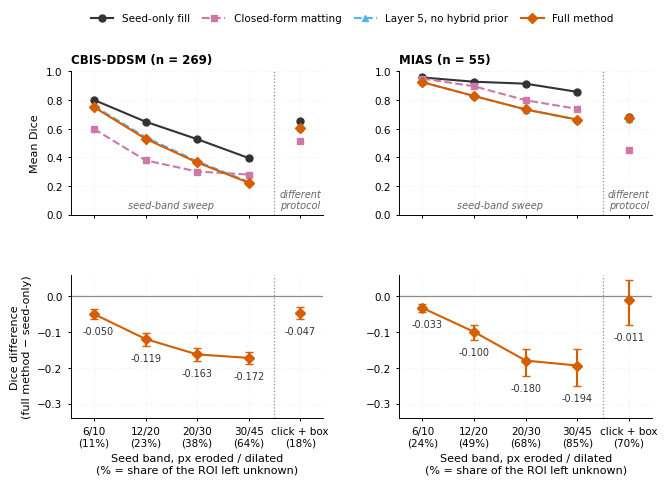

In [50]:
# ################ CELL 1 of 2: FIGURE 4 CONTROLS (paste into the existing CONTROLS cell, run) ################
# ======================= FIGURE 4  -  CONTROLS (edit here) : seed-information sweep ===================
# Top row: mean Dice of four methods as the seed band widens. Bottom row: full method minus seed-only fill (95% CI).
F4_DATASETS   = ['CBIS-DDSM', 'MIAS']          # left-to-right panels; delete one to show a single dataset
F4_METHODS    = ['seed_only', 'closed_form', 'no_hybrid', 'full']      # which lines to draw (names are defined in the main cell)
F4_FIG_W, F4_FIG_H = 7.5, 4.5                    # inches
F4_HSPACE, F4_WSPACE = 0.42, 0.30                 # space between rows / between columns (fraction of the panel size)
F4_FONT       = dict(title=8.5, axis_label=8, tick=7.5, legend=7.5, annotation=7)       # points
F4_LINE_W, F4_MARKER_S = 1.5, 5.0
F4_YLIM_TOP, F4_YLIM_GAP = (0.0, 1.0), (-0.34, 0.06)      # y ranges of the two rows; None = automatic
F4_SHOW_UNKNOWN_FRAC = True                    # second tick-label line: share of the ROI left unknown
F4_SHOW_BOX_SEPARATOR = True                   # dotted line before the click + box protocol
F4_BREAK_LAST = True                           # True: the click + box point is NOT joined to the seed-band lines (it is a different protocol)
F4_SHOW_GROUP_LABELS = True                    # small italic labels 'seed-band sweep' / 'different protocol' inside the top panels

# ################ CELL 2 of 2: FIGURE 4 DRAW (paste into the existing DRAW cell, run right after) ################
# ======================= FIGURE 4  -  DRAW (run, do not edit) =======================================
fig, axes = plt.subplots(2, len(F4_DATASETS), figsize=(F4_FIG_W, F4_FIG_H), sharex='col', squeeze=False, gridspec_kw=dict(hspace=F4_HSPACE, wspace=F4_WSPACE))
x = np.arange(len(SEED_SETTINGS))
for j, ds in enumerate(F4_DATASETS):
    a, b = axes[0][j], axes[1][j]
    for m in F4_METHODS:
        st = METHOD_STYLE[m]; y = np.array(SEED_MEAN[ds][m]); k = len(x) - 1 if F4_BREAK_LAST else len(x)
        a.plot(x[:k], y[:k], color=st['color'], marker=st['marker'], ls=st['ls'], lw=F4_LINE_W, ms=F4_MARKER_S, label=st['label'])
        if F4_BREAK_LAST: a.plot(x[k:], y[k:], color=st['color'], marker=st['marker'], ls='none', ms=F4_MARKER_S)
    a.set_title(f'{ds} (n = {SEED_N[ds]})', fontsize=F4_FONT['title'], loc='left'); a.set_ylabel('Mean Dice' if j == 0 else '', fontsize=F4_FONT['axis_label'])
    if F4_YLIM_TOP: a.set_ylim(*F4_YLIM_TOP)
    g = np.array(SEED_GAP[ds]); b.axhline(0, color=PALETTE['grey'], lw=0.9)
    k = len(x) - 1 if F4_BREAK_LAST else len(x)
    b.errorbar(x[:k], g[:k, 0], yerr=[g[:k, 0] - g[:k, 1], g[:k, 2] - g[:k, 0]], color=PALETTE['verm'], marker='D', ms=F4_MARKER_S, lw=F4_LINE_W, capsize=3, label='Full method - seed-only fill')
    if F4_BREAK_LAST: b.errorbar(x[k:], g[k:, 0], yerr=[g[k:, 0] - g[k:, 1], g[k:, 2] - g[k:, 0]], color=PALETTE['verm'], marker='D', ms=F4_MARKER_S, lw=F4_LINE_W, capsize=3, ls='none')
    b.set_ylabel('Dice difference\n(full method − seed-only)' if j == 0 else '', fontsize=F4_FONT['axis_label'])
    if F4_YLIM_GAP: b.set_ylim(*F4_YLIM_GAP)
    tl = [f'{s}\n({int(round(100 * u))}%)' if F4_SHOW_UNKNOWN_FRAC else s for s, u in zip(SEED_SETTINGS, UNKNOWN_FRAC[ds])]
    b.set_xlim(-0.45, len(x) - 0.55); b.set_xticks(x); b.set_xticklabels(tl, fontsize=F4_FONT['tick']); b.set_xlabel('Seed band, px eroded / dilated\n(% = share of the ROI left unknown)', fontsize=F4_FONT['axis_label'])
    for ax in (a, b):
        ax.tick_params(axis='y', labelsize=F4_FONT['tick'])
        if F4_SHOW_BOX_SEPARATOR: ax.axvline(len(x) - 1.5, color=PALETTE['grey'], ls=':', lw=0.9)
    for k, (xi, (mv, lo, hi)) in enumerate(zip(x, SEED_GAP[ds])):
        b.annotate(f'{mv:+.3f}', (xi, lo), xytext=(-8 if k == 0 else 0, -11), textcoords='offset points', ha='left' if k == 0 else 'center', fontsize=F4_FONT['annotation'], color=PALETTE['dark'])
hh, ll = axes[0][0].get_legend_handles_labels()
fig.legend(hh, ll, loc='upper center', ncol=len(F4_METHODS), fontsize=F4_FONT['legend'], bbox_to_anchor=(0.5, 1.03), columnspacing=1.2, handlelength=2.2)
if F4_SHOW_GROUP_LABELS:
    for j in range(len(F4_DATASETS)):
        axes[0][j].text(1.5, 0.03, 'seed-band sweep', ha='center', va='bottom', fontsize=F4_FONT['annotation'], style='italic', color='#666666')
        axes[0][j].text(len(x) - 1, 0.03, 'different\nprotocol', ha='center', va='bottom', fontsize=F4_FONT['annotation'], style='italic', color='#666666')
save(fig, 'fig04_seed_information_sweep'); plt.show()

## Figure 5 - Classifier AUC on the unknown band (full width)
Edit only the **CONTROLS** cell; then run the **DRAW** cell.

  saved fig05a_classifier_auc_ddsm.png / .pdf


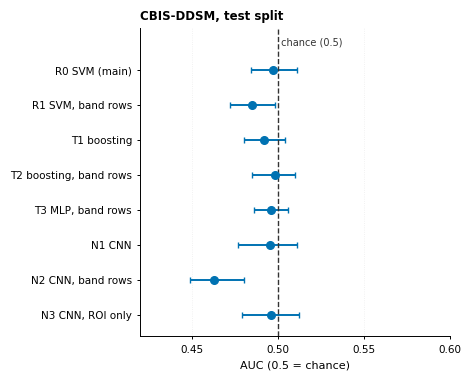

  saved fig05b_classifier_auc_mias.png / .pdf


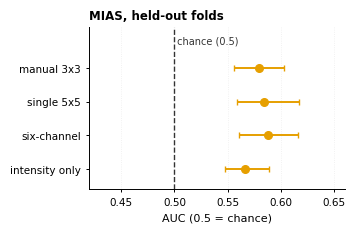

In [51]:
# ################ CELL 1 of 2: FIGURE 5a/5b CONTROLS (paste into the existing Figure 5 CONTROLS cell, run) ################
# ======================= FIGURE 5a / 5b  -  CONTROLS (edit here) : classifier AUC on the unknown band ===
# 5a = CBIS-DDSM (test split), 5b = MIAS (held-out folds). Two separate figures, each with its own size and look.
# ---- Figure 5a (CBIS-DDSM) ----
F5A_FIG_W, F5A_FIG_H = 4, 4             # inches (3.3 = Springer single column, 6.85 = full width)
F5A_XLIM            = (0.42, 0.60)          # AUC axis range; None = automatic
F5A_SHOW_INSIDE_SEEDS = False               # True adds hollow markers: AUC on held-out pixels INSIDE the seeds
# ---- Figure 5b (MIAS) ----
F5B_FIG_W, F5B_FIG_H = 3.3, 2.1             # inches
F5B_XLIM            = (0.42, 0.66)          # None = automatic
# ---- shared by both ----
F5_FONT       = dict(title=8.5, axis_label=8, tick=7.5, legend=7.5, annotation=7)     # points
F5_MARKER_S, F5_LINE_W = 5.5, 1.4
F5_TICK_STEP = 0.05                         # spacing of the AUC axis ticks
F5_SHOW_USEFUL_LINE = False                 # dashed line at AUC = 0.60. Keep OFF unless 0.60 is a pre-specified threshold you state in the Methods

# ################ CELL 2 of 2: FIGURE 5a/5b DRAW (paste into the existing Figure 5 DRAW cell, run right after) ################
# ======================= FIGURE 5a / 5b  -  DRAW (run, do not edit) =================================
def auc_figure(rows, title, fig_w, fig_h, xlim, color, name, inside=None):
    fig, ax = plt.subplots(figsize=(fig_w, fig_h)); y = np.arange(len(rows))[::-1]
    lab, v, lo, hi = zip(*[r[:4] for r in rows])
    ax.errorbar(v, y, xerr=[np.array(v) - lo, np.array(hi) - np.array(v)], fmt='o', color=color, ms=F5_MARKER_S, lw=F5_LINE_W, capsize=2.5, label='unknown band (95% CI)')
    if inside is not None: ax.plot(inside, y, 'o', mfc='white', mec=PALETTE['grey'], ms=F5_MARKER_S, label='inside the seeds'); ax.legend(loc='lower right', fontsize=F5_FONT['legend'])
    ax.axvline(AUC_CHANCE, color=PALETTE['dark'], lw=1.0, ls='--')
    if F5_SHOW_USEFUL_LINE: ax.axvline(AUC_USEFUL, color=PALETTE['green'], lw=1.0, ls='--')
    ax.set_yticks(y); ax.set_yticklabels(lab, fontsize=F5_FONT['tick']); ax.tick_params(axis='x', labelsize=F5_FONT['tick']); ax.grid(axis='y', alpha=0)
    ax.set_xlabel('AUC (0.5 = chance)', fontsize=F5_FONT['axis_label']); ax.set_title(title, fontsize=F5_FONT['title'], loc='left')
    if xlim: ax.set_xlim(*xlim)
    ax.xaxis.set_major_locator(mpl.ticker.MultipleLocator(F5_TICK_STEP))
    ax.text(AUC_CHANCE, len(rows) - 0.35, ' chance (0.5)', fontsize=F5_FONT['annotation'], ha='left', va='bottom', color=PALETTE['dark'])
    if F5_SHOW_USEFUL_LINE: ax.text(AUC_USEFUL, len(rows) - 0.35, ' 0.60', fontsize=F5_FONT['annotation'], ha='left', va='bottom', color=PALETTE['green'])
    ax.set_ylim(-0.6, len(rows) + 0.2); save(fig, name); plt.show()
auc_figure(AUC_DDSM, 'CBIS-DDSM, test split', F5A_FIG_W, F5A_FIG_H, F5A_XLIM, PALETTE['blue'], 'fig05a_classifier_auc_ddsm',
           inside=[r[4] for r in AUC_DDSM] if F5A_SHOW_INSIDE_SEEDS else None)
auc_figure(AUC_MIAS, 'MIAS, held-out folds', F5B_FIG_W, F5B_FIG_H, F5B_XLIM, PALETTE['orange'], 'fig05b_classifier_auc_mias')

## Figure 6 - Per-image paired Dice difference (single column)
Edit only the **CONTROLS** cell; then run the **DRAW** cell.

In [52]:
# ======================= FIGURE 6  -  CONTROLS (edit here) : per-image paired Dice difference =========
SETTING      = 'band 6/10 (default)'        # seed setting taken from seed_sweep_per_image.csv (see the printed list if the name is not found)
FIG_W, FIG_H = 4, 3.5                     # inches (single column)
FONT         = dict(axis_label=8, tick=7.5, legend=7, annotation=7)        # points
LINE_W       = 1.4
XLIM         = (-0.5, 0.5)                  # None = automatic
SHOW_OVERALL = True                         # thick dark curve over all classes
SHOW_FRACTION = True                        # annotate the share of images where the full method is worse

  saved fig06_paired_dice_difference.png / .pdf


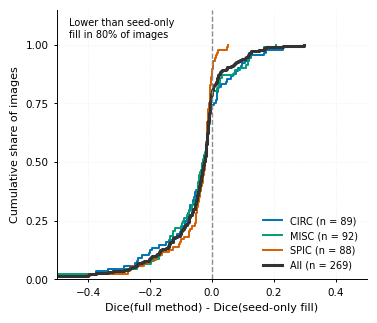

In [53]:
# ======================= FIGURE 6  -  DRAW (run, do not edit) =======================================
S = load_sweep()
if SETTING not in set(S['setting']): raise ValueError(f'Setting not found. Available: {sorted(S["setting"].unique())}')
pv = S[S['setting'] == SETTING].pivot_table(index=['image_id', 'class'], columns='method', values='dice').reset_index()
pv['diff'] = pv['full_method'] - pv['seed_only_distance']
fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))
def ecdf(ax, v, **kw): v = np.sort(np.asarray(v)); ax.step(v, np.arange(1, len(v) + 1) / len(v), where='post', **kw)
for c in ('CIRC', 'MISC', 'SPIC'):
    d = pv[pv['class'] == c]['diff'].dropna()
    if len(d): ecdf(ax, d, color=CLASS_COL[c], lw=LINE_W, label=f'{c} (n = {len(d)})')
if SHOW_OVERALL: ecdf(ax, pv['diff'].dropna(), color=PALETTE['dark'], lw=LINE_W + 0.8, label=f'All (n = {len(pv)})')
ax.axvline(0, color=PALETTE['grey'], lw=1.0, ls='--')
if SHOW_FRACTION:
    worse = (pv['diff'] < 0).mean()
    ax.text(0.04, 0.97, f'Lower than seed-only \nfill in {100 * worse:.0f}% of images', transform=ax.transAxes,
            fontsize=FONT['annotation'], va='top', ha='left', linespacing=1.25)
ax.set_xlabel('Dice(full method) - Dice(seed-only fill)', fontsize=FONT['axis_label']); ax.set_ylabel('Cumulative share of images', fontsize=FONT['axis_label'])
ax.tick_params(labelsize=FONT['tick']); ax.set_ylim(0, 1.15); ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
if XLIM: ax.set_xlim(*XLIM)
ax.legend(loc='lower right', fontsize=FONT['legend'])
save(fig, 'fig06_paired_dice_difference'); plt.show()